# Chapitre 6 - Cours 6 : moteurs de synchronisation, local-first et CRDT

Le cours 3 a présenté la réplication multi-leader entre régions. Poussée à l'extrême,
elle décrit aussi les applications qui fonctionnent **hors ligne** et celles qui
permettent la **collaboration en temps réel** : chaque appareil, voire chaque onglet de
navigateur, devient un leader. Ce cours, propre à la 2e édition, couvre la section *Sync
Engines and Local-First Software* et la partie *Automatic conflict resolution* /
*Conflict-free replicated datatypes and operational transformation* de *Dealing with
Conflicting Writes*. Le code est dans [`ddia/crdt.py`](../../ddia/crdt.py).

**Plan.**

1. Un leader par appareil : les moteurs de synchronisation.
2. Temps réel, hors ligne d'abord, local-first.
3. Avantages et limites d'un moteur de synchronisation.
4. CRDT : compteurs et ensembles qui convergent tout seuls.
5. Texte collaboratif : transformation opérationnelle contre CRDT.

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import crdt
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Un leader par appareil (section *Sync Engines and Local-First Software*)

L'agenda de votre téléphone, de votre portable et de votre tablette doit rester
consultable **et modifiable** sans connexion ; les modifications faites hors ligne sont
synchronisées avec le serveur et les autres appareils au retour du réseau. Chaque
appareil a donc une **base locale qui accepte les écritures** (un leader), et une
réplication multi-leader asynchrone, la **synchronisation**, relie les répliques ; le
retard peut atteindre des heures ou des jours. C'est la configuration multi-régions du
cours 3 poussée à l'extrême : chaque appareil est une « région », reliée aux autres par
un réseau extrêmement peu fiable.

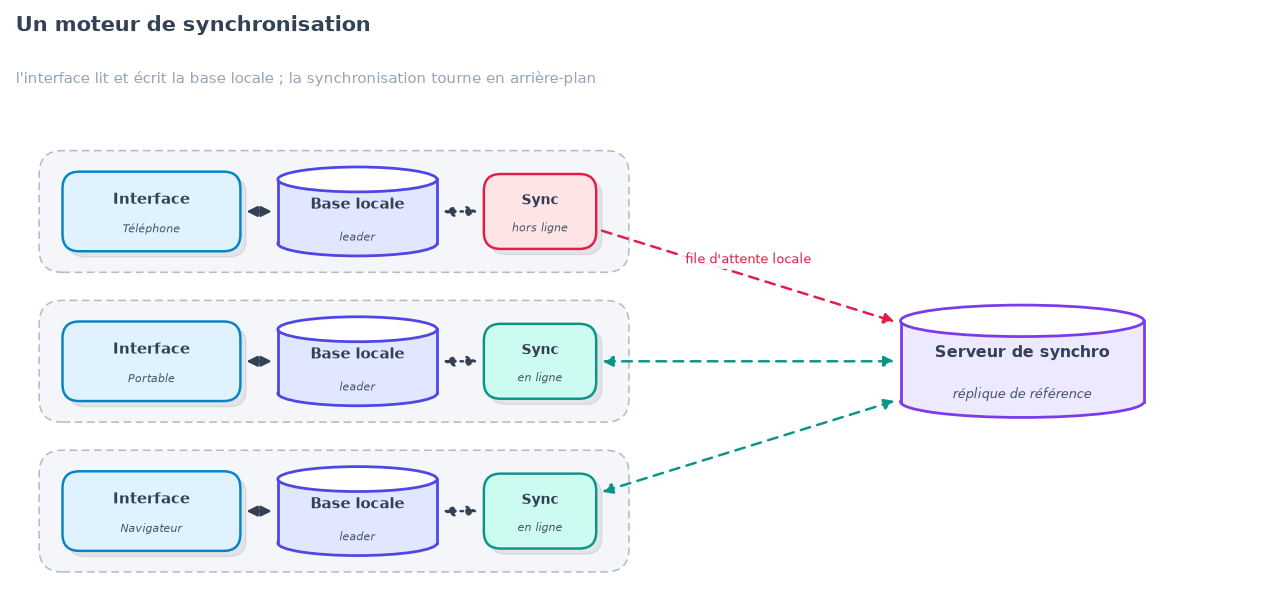

In [2]:
d = Diagram(13.5, 5.2, title="Un moteur de synchronisation",
            subtitle="l'interface lit et écrit la base locale ; la synchronisation tourne en arrière-plan")
for i, (nom, y, etat) in enumerate([("Téléphone", 4.0, "hors ligne"), ("Portable", 2.4, "en ligne"), ("Navigateur", 0.8, "en ligne")]):
    d.group(0.3, y - 0.65, 6.6, y + 0.65, None, color=SLATE)
    d.box(f"ui{i}", 1.5, y, "Interface", sub=nom, color=SKY, w=1.9, h=0.85, fontsize=9.5)
    d.box(f"db{i}", 3.7, y, "Base locale", sub="leader", color=INDIGO, kind="db", w=1.7, h=0.95, fontsize=9.5)
    d.box(f"se{i}", 5.65, y, "Sync", sub=etat, color=ROSE if etat == "hors ligne" else TEAL, w=1.2, h=0.8, fontsize=9)
    d.arrow(f"ui{i}", f"db{i}", both=True)
    d.arrow(f"db{i}", f"se{i}", both=True, style="dotted")
d.box("srv", 10.8, 2.4, "Serveur de synchro", sub="réplique de référence", color=VIOLET, kind="db", w=2.6, h=1.2)
d.arrow("se0", "srv", "file d'attente locale", style="dashed", color=ROSE)
d.arrow("se1", "srv", both=True, style="dashed", color=TEAL)
d.arrow("se2", "srv", both=True, style="dashed", color=TEAL)
d.show()

> **À retenir.** Une application qui doit fonctionner hors ligne est un système
> multi-leader : chaque appareil accepte des écritures et se synchronise plus tard,
> avec un retard potentiellement très long.

## 2. Temps réel, hors ligne d'abord, local-first (section *Real-time collaboration, offline-first, and local-first apps*)

Les applications collaboratives modernes (éditeurs de documents, de tableurs, de
graphismes, gestion de projets) affichent la saisie **immédiatement**, sans attendre un
aller-retour au serveur, et montrent les modifications des collaborateurs avec une faible
latence. C'est encore du multi-leader : chaque onglet ouvert sur le document est une
réplique, et les modifications sont répliquées de façon asynchrone. Même sans mode hors
ligne, le fait que chacun puisse modifier sans attendre de réponse du serveur suffit.

Vocabulaire :

- **moteur de synchronisation** (sync engine) : la bibliothèque qui capture les
  modifications locales, les envoie (ou les met en file si hors ligne), reçoit celles des
  autres, les fusionne dans la copie locale et met à jour l'interface ;
- **hors ligne d'abord** (offline-first) : une application qui continue de fonctionner
  hors ligne ;
- **local-first** : une application collaborative hors ligne d'abord, conçue pour
  continuer de fonctionner **même si son éditeur ferme tous ses services en ligne**, par
  exemple grâce à un protocole de synchronisation ouvert proposé par plusieurs
  hébergeurs. Git en est un exemple (sans temps réel) : on peut synchroniser via
  n'importe quel hébergeur.

**Pourquoi c'est si réactif.** Une écriture locale prend une fraction de milliseconde ;
une requête au serveur, un aller-retour réseau. Certaines applications visent à répondre
dans l'**image suivante** : 16 ms à 60 Hz. Comparons, avec des allers-retours typiques
(fibre, 4G, réseau mobile dégradé).

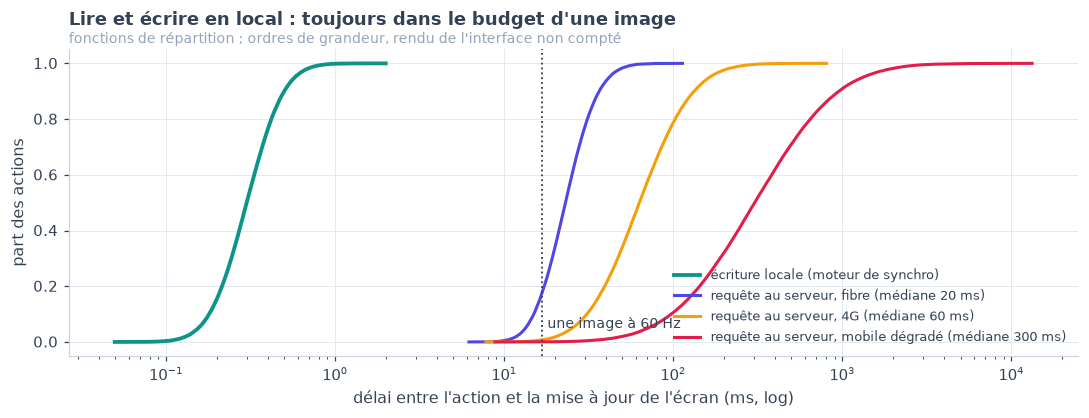

,local,fibre (médiane 20 ms),4G (médiane 60 ms),mobile dégradé (médiane 300 ms)
"% des actions sous 16,7 ms",100.0,17.4,0.7,0.0


In [3]:
N = 100000
local = rng.lognormal(np.log(0.3), 0.4, N)
reseaux = {"fibre (médiane 20 ms)": rng.lognormal(np.log(20), 0.4, N) + 3,
           "4G (médiane 60 ms)": rng.lognormal(np.log(60), 0.6, N) + 3,
           "mobile dégradé (médiane 300 ms)": rng.lognormal(np.log(300), 0.9, N) + 3}
fig, ax = plt.subplots(figsize=(10, 3.9))
ax.plot(np.sort(local), np.arange(1, N + 1) / N, color=TEAL, lw=2.5, label="écriture locale (moteur de synchro)")
for (k, v), c in zip(reseaux.items(), [INDIGO, AMBER, ROSE]):
    ax.plot(np.sort(v), np.arange(1, N + 1) / N, color=c, label=f"requête au serveur, {k}")
ax.axvline(16.7, color=SLATE, ls=":", lw=1.2); ax.text(18, 0.05, "une image à 60 Hz", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("délai entre l'action et la mise à jour de l'écran (ms, log)")
ax.set_ylabel("part des actions")
ax.set_title("Lire et écrire en local : toujours dans le budget d'une image")
subtitle(ax, "fonctions de répartition ; ordres de grandeur, rendu de l'interface non compté")
ax.legend(fontsize=8.5, loc="lower right")
plt.tight_layout(); plt.show()
pd.DataFrame({k: [100 * np.mean(v <= 16.7)] for k, v in {"local": local, **reseaux}.items()},
             index=["% des actions sous 16,7 ms"]).round(1)

Toutes les écritures locales tiennent dans le budget d'une image ; sur fibre, moins d'une
requête au serveur sur cinq y parvient, et pratiquement aucune en 4G. C'est l'argument central des moteurs de synchronisation :
la latence réseau sort du chemin critique de l'interface.

> **À retenir.** Collaboration en temps réel et fonctionnement hors ligne reposent sur
> la même infrastructure : une réplique locale qui accepte les écritures et un moteur de
> synchronisation ; local-first ajoute l'indépendance vis-à-vis d'un fournisseur.

## 3. Avantages et limites d'un moteur de synchronisation (section *Pros and cons of sync engines*)

Aujourd'hui, la plupart des applications web gardent très peu d'état sur le client et
interrogent le serveur à chaque besoin. Un moteur de synchronisation garde au contraire
un état **persistant** sur le client et relègue la communication en arrière-plan. Les
avantages listés par le livre :

- une interface bien plus réactive (section 2) ;
- pas de « mode hors ligne » séparé : **être hors ligne, c'est juste avoir un très grand
  délai réseau** ;
- un modèle de programmation plus simple : lire et écrire localement n'échoue presque
  jamais, alors que chaque appel de service exige une gestion d'erreur (chapitre
  5), d'où un style plus déclaratif ;
- combiné à une programmation réactive, un moyen naturel d'afficher en direct les
  modifications des autres.

Illustrons « hors ligne = grand délai » : un téléphone alterne périodes connectées et
déconnectées au cours d'une journée ; l'utilisateur fait des modifications à toute heure.
Chaque modification attend dans la file locale jusqu'à la prochaine connexion.

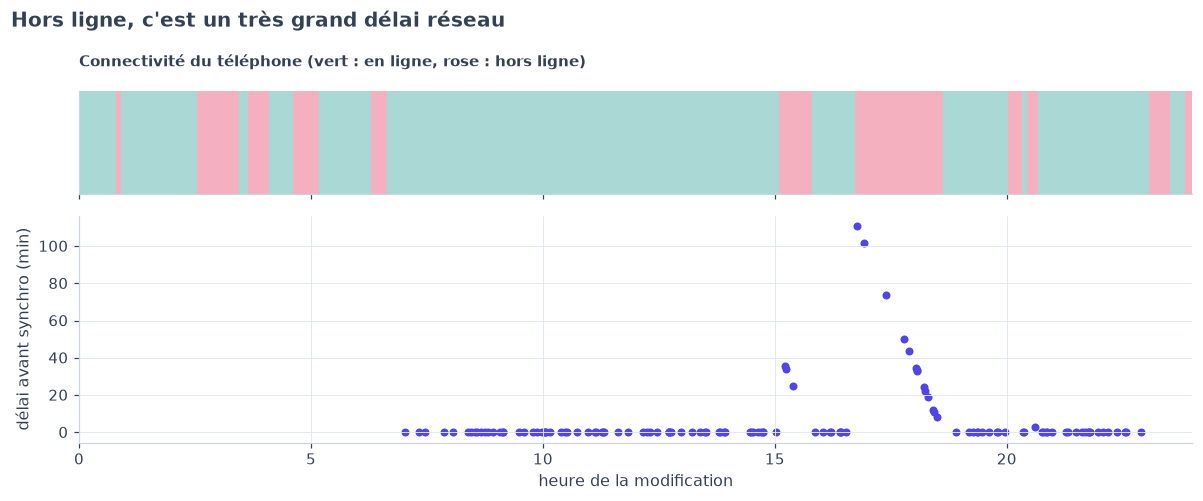

modifications synchronisées immédiatement : 85 % ; délai médian des autres : 33 min ; maximum : 111 min


In [4]:
heures = 24
t_mod = np.sort(rng.uniform(7, 23, 120))                       # 120 modifications entre 7 h et 23 h
bornes, t, connecte = [], 0.0, True
while t < heures:                                              # périodes alternées
    duree = rng.exponential(1.5 if connecte else 1.0)
    bornes.append((t, min(heures, t + duree), connecte))
    t += duree; connecte = not connecte
def prochaine_connexion(x):
    for a, b, c in bornes:
        if c and b > x:
            return max(a, x)
    return heures
delai = np.array([prochaine_connexion(x) - x for x in t_mod]) * 60
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 4.6), height_ratios=[1, 2.2], sharex=True)
for a, b, c in bornes:
    ax1.axvspan(a, b, color=TEAL if c else ROSE, alpha=0.35, lw=0)
ax1.set_yticks([]); ax1.grid(False); ax1.set_title("Connectivité du téléphone (vert : en ligne, rose : hors ligne)", fontsize=10)
ax2.scatter(t_mod, delai, s=18, color=INDIGO)
ax2.set_xlabel("heure de la modification"); ax2.set_ylabel("délai avant synchro (min)")
ax2.set_xlim(0, 24)
finish(fig, "Hors ligne, c'est un très grand délai réseau")
plt.show()
print(f"modifications synchronisées immédiatement : {np.mean(delai == 0) * 100:.0f} % ; "
      f"délai médian des autres : {np.median(delai[delai > 0]):.0f} min ; maximum : {delai.max():.0f} min")

La plupart des modifications (85 %) partent aussitôt, les autres attendent souvent une
demi-heure, parfois près de deux heures,
dans la file locale ; l'application, elle, a fonctionné exactement de la même façon dans
les deux cas. Le revers apparaît au cours 3 (section 4) : avec un délai $L$ de l'ordre de
l'heure, la probabilité de conflit $1 - e^{-\lambda L}$ n'est plus négligeable dès qu'une
donnée est partagée. D'où l'importance d'une fusion **automatique** (sections 4 et 5).

**La limite principale : la taille des données.** Un moteur de synchronisation marche
d'autant mieux que **toutes** les données utiles sont téléchargées à l'avance. C'est
raisonnable pour les documents d'un utilisateur, pas pour le catalogue entier d'un site
marchand. L'idée n'est pas neuve (Lotus Notes, dans les années 1980) ; on trouve
aujourd'hui des moteurs adossés à un service propriétaire (Firestore, Realm, Ditto) et
d'autres à un serveur libre, adaptés au local-first (PouchDB/CouchDB, Automerge, Yjs).
Les jeux vidéo multijoueurs ont un besoin voisin, le *netcode*, aux techniques trop
spécifiques pour être généralisées.

> **À retenir.** Un moteur de synchronisation rend l'interface rapide, unifie les modes
> connecté et hors ligne et simplifie le code client, mais suppose que les données d'un
> utilisateur tiennent sur son appareil et impose de fusionner des conflits.